# Lab 2 - Phần 2.2: Support Vector Machine (SVM)
**Nội dung:** bài mẫu (Iris, MNIST digits) + Bài tập 1 (Diabetes) + Bài tập 2 (Animal Condition).

**Dữ liệu:** `diabetes.csv`, file dữ liệu Animal Condition (ví dụ `animal_disease_dataset.csv`). Iris và digits có sẵn trong scikit-learn.

In [1]:
import sys; sys.path.append(".")
from utils import *
from sklearn import datasets
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, GridSearchCV, cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix

## A. Bài làm mẫu 1 - Iris (phân loại 3 lớp)

Tên lớp: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')] | Shape: (150, 4)


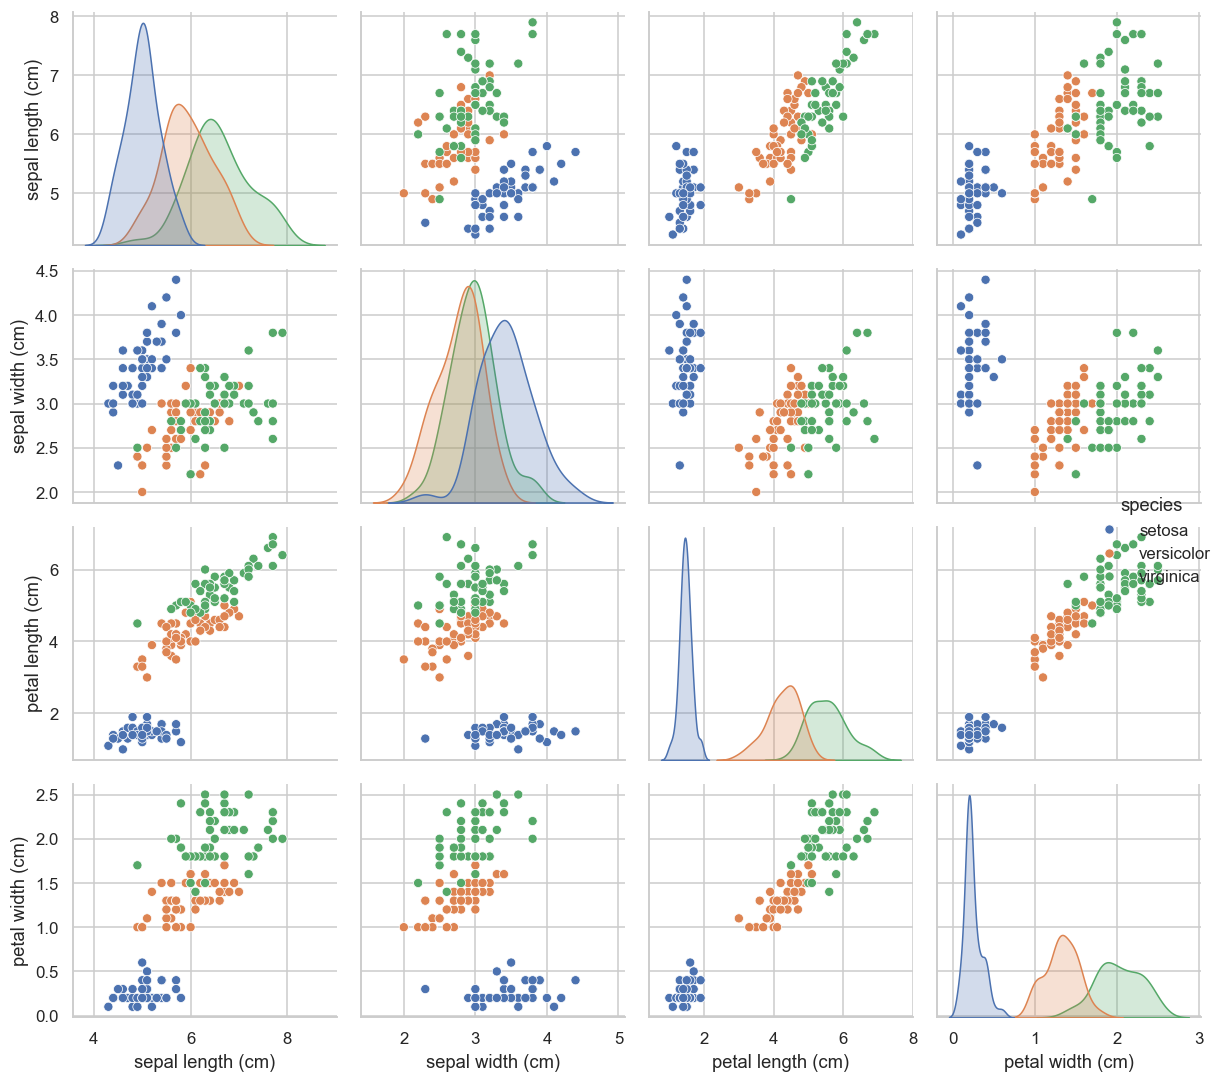

[Đã lưu] figures\s22_iris_pairplot.png


In [2]:
iris = datasets.load_iris(as_frame=True)
Xi, yi = iris.data, iris.target
print("Tên lớp:", list(iris.target_names), "| Shape:", Xi.shape)
sns.pairplot(pd.concat([Xi, iris.target.map(dict(enumerate(iris.target_names))).rename("species")], axis=1), hue="species")
save_fig("s22_iris_pairplot")

Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(Xi, yi, test_size=0.2, random_state=101, stratify=yi)

In [3]:
# Ảnh hưởng của kernel (chọn kernel bằng cross-validation trên tập train, KHÔNG chọn bằng tập test)
rows = []
for k in ["linear", "poly", "rbf", "sigmoid"]:
    m = SVC(kernel=k).fit(Xi_tr, yi_tr)
    cv_acc = cross_val_score(SVC(kernel=k), Xi_tr, yi_tr, cv=5).mean()
    rows.append([k, cv_acc, accuracy_score(yi_te, m.predict(Xi_te))])
display(pd.DataFrame(rows, columns=["kernel", "CV accuracy (train)", "Test accuracy"]).round(4))

,kernel,CV accuracy (train),Test accuracy
0,linear,0.9833,0.9667
1,poly,0.9750,0.9667
2,rbf,0.9583,0.9667
3,sigmoid,0.0750,0.0333


Tham số tốt nhất: {'C': 10, 'gamma': 0.1, 'kernel': 'rbf'} | CV acc = 0.9917

===== Iris SVM =====
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       1.00      0.90      0.95        10
   virginica       0.91      1.00      0.95        10

    accuracy                           0.97        30
   macro avg       0.97      0.97      0.97        30
weighted avg       0.97      0.97      0.97        30



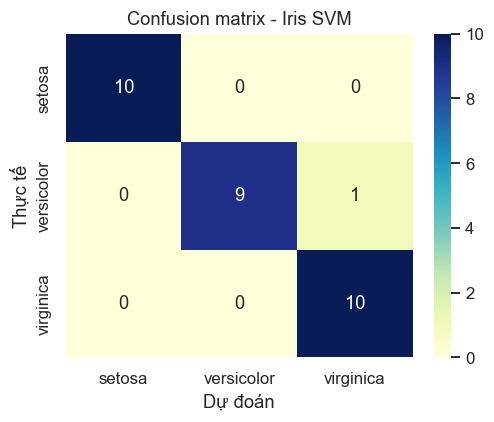

[Đã lưu] figures\cm_iris_svm.png


In [4]:
# Tối ưu C, gamma, kernel bằng GridSearchCV
param_grid = {"C": [0.1, 1, 10, 100], "gamma": [1, 0.1, 0.01, 0.001], "kernel": ["rbf", "linear", "poly"]}
grid = GridSearchCV(SVC(), param_grid, refit=True, cv=5).fit(Xi_tr, yi_tr)
print("Tham số tốt nhất:", grid.best_params_, "| CV acc =", round(grid.best_score_, 4))
res_iris = evaluate_model(grid.best_estimator_, Xi_te, yi_te, "Iris SVM", list(iris.target_names))

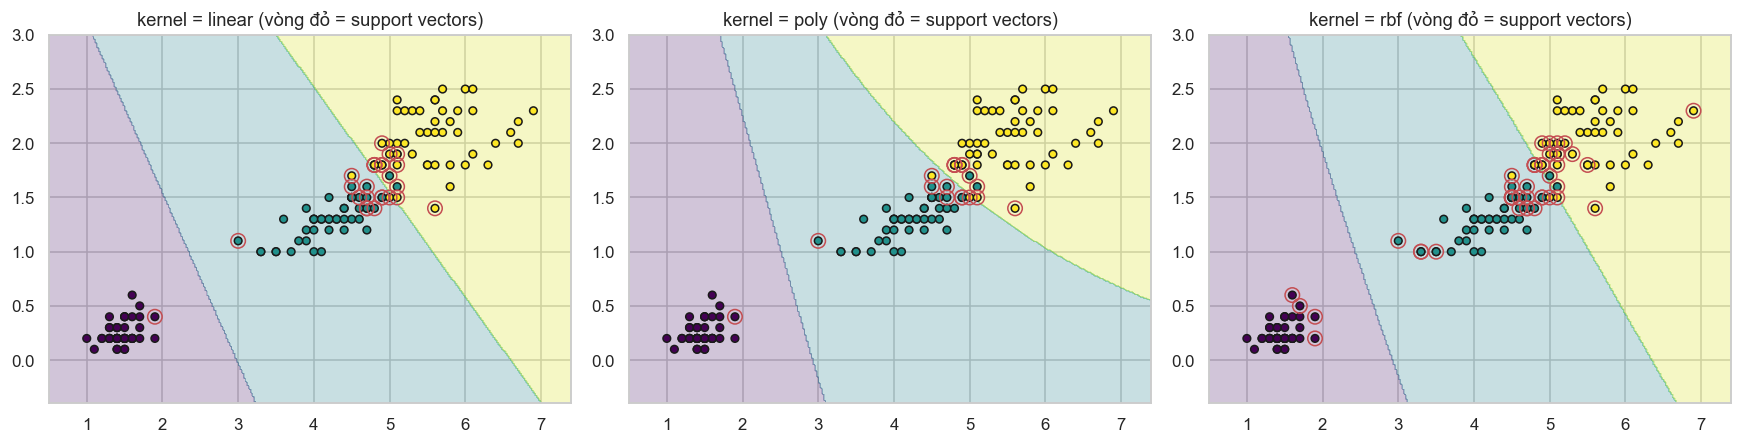

[Đã lưu] figures\s22_iris_decision_boundary.png


In [5]:
# Minh họa ranh giới quyết định (2 đặc trưng: petal length, petal width) cho 3 kernel
Xp = Xi[["petal length (cm)", "petal width (cm)"]].values
fig, axs = plt.subplots(1, 3, figsize=(16, 4.2))
xx, yy = np.meshgrid(np.linspace(Xp[:, 0].min() - .5, Xp[:, 0].max() + .5, 300),
                     np.linspace(Xp[:, 1].min() - .5, Xp[:, 1].max() + .5, 300))
for ax, k in zip(axs, ["linear", "poly", "rbf"]):
    m = SVC(kernel=k, C=1, gamma="scale").fit(Xp, yi)
    Z = m.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, alpha=.25, cmap="viridis")
    ax.scatter(Xp[:, 0], Xp[:, 1], c=yi, cmap="viridis", edgecolor="k", s=25)
    ax.scatter(*m.support_vectors_.T, s=90, facecolors="none", edgecolors="r", linewidths=1)
    ax.set_title(f"kernel = {k} (vòng đỏ = support vectors)")
save_fig("s22_iris_decision_boundary")

## B. Bài làm mẫu 2 - Nhận dạng chữ số viết tay (digits, ảnh 8x8)

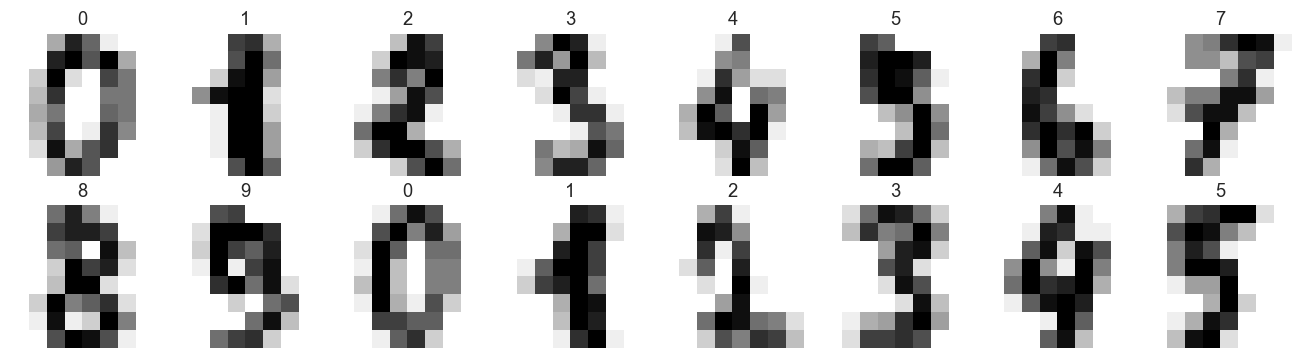

[Đã lưu] figures\s22_digits_samples.png


In [6]:
digits = datasets.load_digits()
fig, axs = plt.subplots(2, 8, figsize=(12, 3.4))
for ax, img, lab in zip(axs.ravel(), digits.images, digits.target):
    ax.imshow(img, cmap="gray_r"); ax.set_title(lab); ax.axis("off")
save_fig("s22_digits_samples")

Xd = digits.images.reshape(len(digits.images), -1)
Xd_tr, Xd_te, yd_tr, yd_te = train_test_split(Xd, digits.target, test_size=0.2, random_state=42, stratify=digits.target)


===== Digits SVM =====
              precision    recall  f1-score   support

           0       1.00      1.00      1.00        36
           1       0.97      1.00      0.99        36
           2       1.00      1.00      1.00        35
           3       1.00      1.00      1.00        37
           4       1.00      1.00      1.00        36
           5       1.00      1.00      1.00        37
           6       1.00      0.97      0.99        36
           7       0.97      1.00      0.99        36
           8       0.97      0.97      0.97        35
           9       1.00      0.97      0.99        36

    accuracy                           0.99       360
   macro avg       0.99      0.99      0.99       360
weighted avg       0.99      0.99      0.99       360



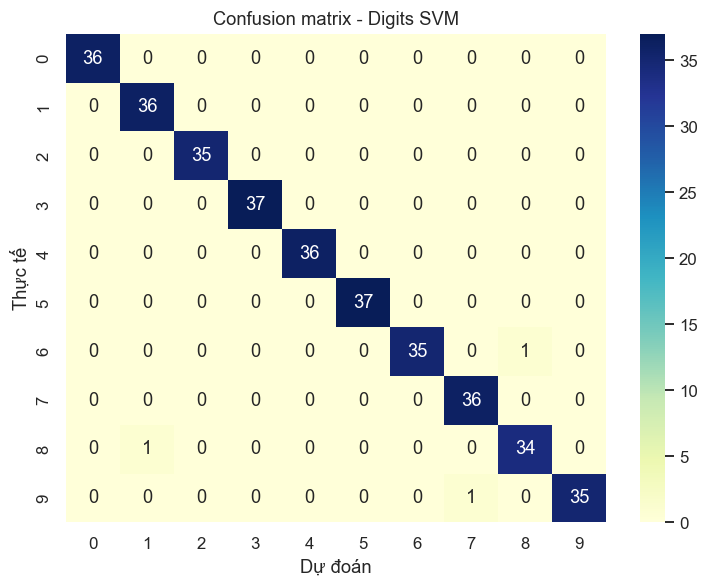

[Đã lưu] figures\cm_digits_svm.png


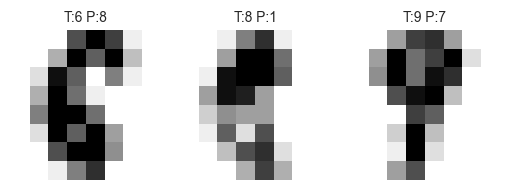

[Đã lưu] figures\s22_digits_errors.png


In [7]:
svm_d = SVC(gamma=0.001, C=100).fit(Xd_tr, yd_tr)
res_digits = evaluate_model(svm_d, Xd_te, yd_te, "Digits SVM", [str(i) for i in range(10)])

# Các ảnh bị phân loại sai
pred = svm_d.predict(Xd_te); wrong = np.where(pred != yd_te)[0][:8]
if len(wrong):
    fig, axs = plt.subplots(1, len(wrong), figsize=(1.6 * len(wrong), 2))
    for ax, i in zip(np.atleast_1d(axs), wrong):
        ax.imshow(Xd_te[i].reshape(8, 8), cmap="gray_r"); ax.set_title(f"T:{yd_te[i]} P:{pred[i]}", fontsize=9); ax.axis("off")
    save_fig("s22_digits_errors")

## C. Bài tập 1 - Diabetes (SVM)

In [8]:
db, target = load_diabetes(clean_zeros=True)
y = db[target]; X = db.drop(columns=target)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

[Đọc dữ liệu] data\diabetes.csv


**1. Tầm quan trọng của chuẩn hóa dữ liệu:** SVM dựa trên khoảng cách nên rất nhạy với thang đo.

In [9]:
from sklearn.impute import SimpleImputer
no_scale = Pipeline([("imp", SimpleImputer(strategy="median")), ("svm", SVC(kernel="rbf"))])
scaled = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("svm", SVC(kernel="rbf"))])
skf = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
for name, p in [("Không chuẩn hóa", no_scale), ("Có StandardScaler", scaled)]:
    s = cross_val_score(p, X_tr, y_tr, cv=skf, scoring="accuracy")
    print(f"{name:18s}: CV accuracy = {s.mean():.4f} ± {s.std():.4f}")

Không chuẩn hóa   : CV accuracy = 0.7671 ± 0.0260
Có StandardScaler : CV accuracy = 0.7801 ± 0.0136


**2. So sánh kernel và tìm tham số tối ưu (GridSearchCV trong Pipeline)**

In [10]:
pipe = Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler()), ("svm", SVC(probability=True, random_state=RANDOM_STATE))])
grid_params = [
    {"svm__kernel": ["linear"], "svm__C": [0.01, 0.1, 1, 10, 100]},
    {"svm__kernel": ["rbf"], "svm__C": [0.1, 1, 10, 100], "svm__gamma": ["scale", 0.1, 0.01, 0.001]},
    {"svm__kernel": ["poly"], "svm__C": [0.1, 1, 10], "svm__degree": [2, 3], "svm__gamma": ["scale", 0.1]},
]
gs = GridSearchCV(pipe, grid_params, cv=skf, scoring="roc_auc", n_jobs=-1, refit=True).fit(X_tr, y_tr)
print("Tham số tốt nhất:", gs.best_params_, "| CV AUC =", round(gs.best_score_, 4))
cvdf = pd.DataFrame(gs.cv_results_)
display(cvdf.groupby("param_svm__kernel")["mean_test_score"].max().round(4).to_frame("CV AUC tốt nhất theo kernel"))

Tham số tốt nhất: {'svm__C': 100, 'svm__gamma': 0.001, 'svm__kernel': 'rbf'} | CV AUC = 0.8464


,CV AUC tốt nhất theo kernel
param_svm__kernel,
linear,0.8459
poly,0.8298
rbf,0.8464



===== Diabetes SVM (tối ưu) =====
              precision    recall  f1-score   support

  Không bệnh       0.74      0.81      0.78       100
     Có bệnh       0.58      0.48      0.53        54

    accuracy                           0.69       154
   macro avg       0.66      0.65      0.65       154
weighted avg       0.69      0.69      0.69       154



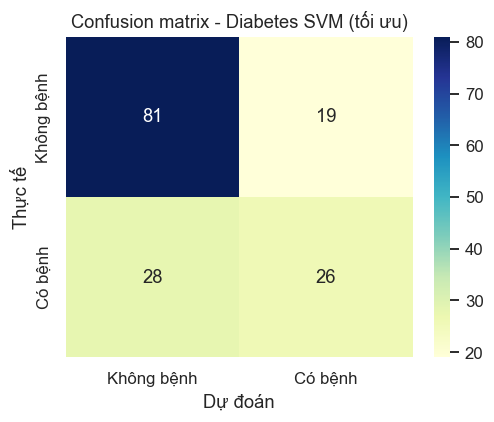

[Đã lưu] figures\cm_diabetes_svm_toi_uu.png


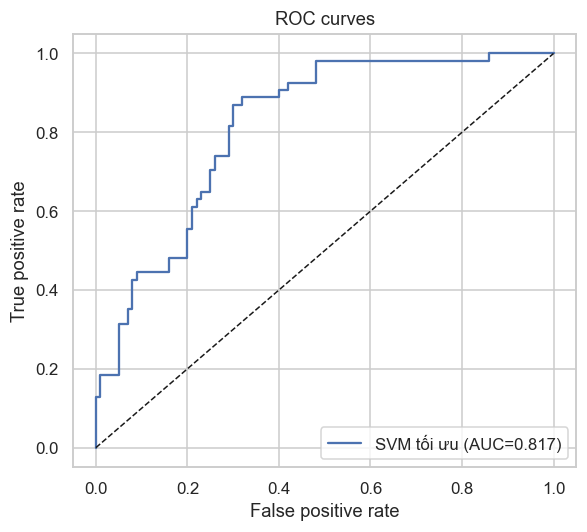

[Đã lưu] figures\s22_diabetes_roc.png


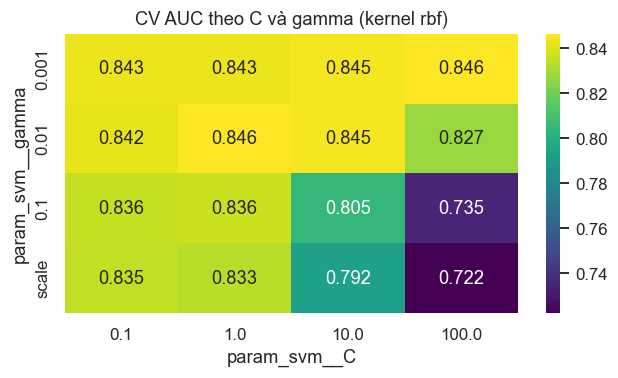

[Đã lưu] figures\s22_diabetes_C_gamma_heatmap.png


In [11]:
res_db = [evaluate_model(gs.best_estimator_, X_te, y_te, "Diabetes SVM (tối ưu)", ["Không bệnh", "Có bệnh"])]
plot_roc({"SVM tối ưu": gs.best_estimator_}, X_te, y_te, "s22_diabetes_roc")

# Ảnh hưởng của C và gamma (heatmap CV AUC cho kernel rbf)
rbf = cvdf[cvdf["param_svm__kernel"] == "rbf"].copy()
hm = rbf.pivot_table(index="param_svm__gamma", columns="param_svm__C", values="mean_test_score", aggfunc="max").astype(float)
plt.figure(figsize=(6, 3.6)); sns.heatmap(hm, annot=True, fmt=".3f", cmap="viridis")
plt.title("CV AUC theo C và gamma (kernel rbf)"); save_fig("s22_diabetes_C_gamma_heatmap")

## D. Bài tập 2 - Animal Condition (SVM, dữ liệu phân loại)

In [12]:
an = load_table("animal*.csv", "*animal*.csv", "*condition*.csv")
overview(an, "Animal Condition")
target_an = guess_column(an, ["Dangerous", "Condition", "Target", "Class", "Label"])
print("Biến mục tiêu:", target_an)
display(an[target_an].value_counts(dropna=False).to_frame("count"))


[Đọc dữ liệu] data\animal_disease_dataset.csv
===== Animal Condition =====
Kích thước: 871 dòng x 7 cột
Số dòng trùng lặp: 28


,dtype,missing,missing_%,n_unique
AnimalName,object,0,0.00,46
symptoms1,object,0,0.00,232
symptoms2,object,0,0.00,230
symptoms3,object,0,0.00,229
symptoms4,object,0,0.00,217
symptoms5,object,0,0.00,203
Dangerous,object,2,0.23,2


,AnimalName,symptoms1,symptoms2,symptoms3,symptoms4,symptoms5,Dangerous
0,Dog,Fever,Diarrhea,Vomiting,Weight loss,Dehydration,Yes
1,Dog,Fever,Diarrhea,Coughing,Tiredness,Pains,Yes
2,Dog,Fever,Diarrhea,Coughing,Vomiting,Anorexia,Yes
3,Dog,Fever,Difficulty breathing,Coughing,Lethargy,Sneezing,Yes
4,Dog,Fever,Diarrhea,Coughing,Lethargy,Blue Eye,Yes


Biến mục tiêu: Dangerous


,count
Dangerous,
Yes,849
No,20
NaN,2


In [13]:
# Chuẩn hóa chuỗi: dữ liệu có khoảng trắng thừa, \xa0, khác biệt hoa/thường (vd "Coughing\xa0" vs "coughing\xa0")
def clean_text(s):
    return s.astype(str).str.replace("\xa0", " ", regex=False).str.strip().str.lower().str.replace(r"\s+", " ", regex=True)

an = an.dropna(subset=[target_an]).copy()
for c in an.select_dtypes(exclude="number").columns:
    an[c] = clean_text(an[c])
animal_col = guess_column(an, ["AnimalName", "Animal"], required=False)
if animal_col:
    an[animal_col] = an[animal_col].replace({"dogs": "dog", "pigs": "pig", "goats": "goat"})
an = an.drop_duplicates()
print("Sau làm sạch:", an.shape)
display(an[target_an].value_counts().to_frame("count"))

y_an = an[target_an].astype(str)
X_an = an.drop(columns=[target_an])
X_tr, X_te, y_tr, y_te = train_test_split(X_an, y_an, test_size=0.2, random_state=RANDOM_STATE, stratify=y_an)
print("Train:", X_tr.shape, "| Test:", X_te.shape, "| Số mẫu lớp thiểu số trong test:", int((y_te == y_te.value_counts().idxmin()).sum()))


Sau làm sạch: (839, 7)


,count
Dangerous,
yes,819
no,20


Train: (671, 6) | Test: (168, 6) | Số mẫu lớp thiểu số trong test: 4


In [14]:
# Toàn bộ đặc trưng là dạng chữ -> One-Hot Encoding trong Pipeline
# Lớp mất cân bằng rất nặng (Yes >> No) -> dùng class_weight="balanced" và đánh giá thêm F1-macro, balanced accuracy
from sklearn.metrics import f1_score, balanced_accuracy_score
res_an, fitted = [], {}
for k in ["linear", "rbf", "poly", "sigmoid"]:
    p = Pipeline([("prep", make_preprocessor(X_an, scale=False)), ("svm", SVC(kernel=k, C=1.0, class_weight="balanced"))]).fit(X_tr, y_tr)
    fitted[k] = p
    r = evaluate_model(p, X_te, y_te, f"Animal SVM {k}", plot=False)
    pred = p.predict(X_te)
    r["f1_macro"] = f1_score(y_te, pred, average="macro", zero_division=0)
    r["balanced_acc"] = balanced_accuracy_score(y_te, pred)
    res_an.append(r)
display(results_table(res_an, sort_by="f1_macro"))



===== Animal SVM linear =====
              precision    recall  f1-score   support

          no       1.00      1.00      1.00         4
         yes       1.00      1.00      1.00       164

    accuracy                           1.00       168
   macro avg       1.00      1.00      1.00       168
weighted avg       1.00      1.00      1.00       168


===== Animal SVM rbf =====
              precision    recall  f1-score   support

          no       1.00      1.00      1.00         4
         yes       1.00      1.00      1.00       164

    accuracy                           1.00       168
   macro avg       1.00      1.00      1.00       168
weighted avg       1.00      1.00      1.00       168


===== Animal SVM poly =====
              precision    recall  f1-score   support

          no       1.00      1.00      1.00         4
         yes       1.00      1.00      1.00       164

    accuracy                           1.00       168
   macro avg       1.00      1.00      1

,accuracy,precision,recall,f1,roc_auc,f1_macro,balanced_acc
model,,,,,,,
Animal SVM linear,1.0000,1.0,1.0000,1.0000,1.0,1.000,1.0000
Animal SVM rbf,1.0000,1.0,1.0000,1.0000,1.0,1.000,1.0000
Animal SVM poly,1.0000,1.0,1.0000,1.0000,1.0,1.000,1.0000
Animal SVM sigmoid,0.9821,1.0,0.9817,0.9908,1.0,0.859,0.9909


Tham số tốt nhất: {'svm__C': 0.1, 'svm__gamma': 'scale', 'svm__kernel': 'rbf'} | CV f1_macro = 0.8697

===== Animal SVM (tối ưu) =====
              precision    recall  f1-score   support

          no       1.00      1.00      1.00         4
         yes       1.00      1.00      1.00       164

    accuracy                           1.00       168
   macro avg       1.00      1.00      1.00       168
weighted avg       1.00      1.00      1.00       168



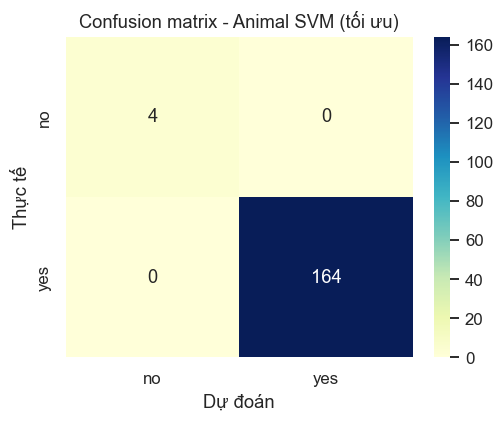

[Đã lưu] figures\cm_animal_svm_toi_uu.png


In [15]:
pipe_an = Pipeline([("prep", make_preprocessor(X_an, scale=False)), ("svm", SVC(class_weight="balanced"))])
# Chấm điểm bằng f1_macro (không dùng accuracy vì lớp mất cân bằng nặng)
gs_an = GridSearchCV(pipe_an, {"svm__kernel": ["linear", "rbf"], "svm__C": [0.1, 1, 10, 100], "svm__gamma": ["scale", 0.1, 0.01]},
                     cv=5, scoring="f1_macro", n_jobs=-1).fit(X_tr, y_tr)
print("Tham số tốt nhất:", gs_an.best_params_, "| CV f1_macro =", round(gs_an.best_score_, 4))
res_best_an = evaluate_model(gs_an.best_estimator_, X_te, y_te, "Animal SVM (tối ưu)")
pred = gs_an.best_estimator_.predict(X_te)
res_best_an["f1_macro"] = f1_score(y_te, pred, average="macro", zero_division=0)
res_best_an["balanced_acc"] = balanced_accuracy_score(y_te, pred)


## E. Tổng hợp

In [16]:
final = results_table([res_iris, res_digits] + res_db + [res_best_an])
display(final); final.to_csv(OUT_DIR / "s22_summary.csv")

,accuracy,precision,recall,f1,roc_auc,f1_macro,balanced_acc
model,,,,,,,
Animal SVM (tối ưu),1.0000,1.0000,1.0000,1.0000,1.0000,1.0,1.0
Digits SVM,0.9917,0.9918,0.9917,0.9917,NaN,NaN,NaN
Iris SVM,0.9667,0.9697,0.9667,0.9666,NaN,NaN,NaN
Diabetes SVM (tối ưu),0.6948,0.5778,0.4815,0.5253,0.8167,NaN,NaN
